<a href="https://colab.research.google.com/github/syifaST/simuteh--2330511062-/blob/main/notebook/B2_Citra_Warna.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os, sys
REPO = "https://github.com/syifaST/simuteh--2330511062-.git"

if not os.path.exists("/content/simuteh"):
    !git clone {REPO} /content/simuteh
os.chdir("/content/simuteh")

for f in ["notebook", "hasil", "laporan"]:
    os.makedirs(f, exist_ok=True)

if not os.path.exists("data/sintetis/citra"):
    !python src/buat_dataset_sintetis.py

os.chdir("/content/simuteh/notebook")
sys.path.append("../src")

print("Folder kerja:", os.getcwd())
print("Jumlah citra:", len(os.listdir("../data/sintetis/citra")))
print("Isi src:", os.listdir("../src"))

Cloning into '/content/simuteh'...
remote: Enumerating objects: 124, done.
remote: Counting objects: 100% (124/124), done.
remote: Compressing objects: 100% (114/114), done.
remote: Total 124 (delta 14), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (124/124), 14.42 MiB | 10.24 MiB/s, done.
Resolving deltas: 100% (14/14), done.
Selesai: 60 citra tersimpan di data/sintetis
Folder kerja: /content/simuteh/notebook
Jumlah citra: 60
Isi src: ['buat_dataset_sintetis.py', 'utils_cv.py']


**2.1 Memisahkan citra
berbercak berat ke kanal dan menghitung KB setiap kanal**

KB kanal B   : 1.51
KB kanal G   : 1.81
KB kanal R   : 8.99
KB kanal Gray: 5.32
KB kanal H   : 5.66
KB kanal S   : 0.58
KB kanal V   : 3.48


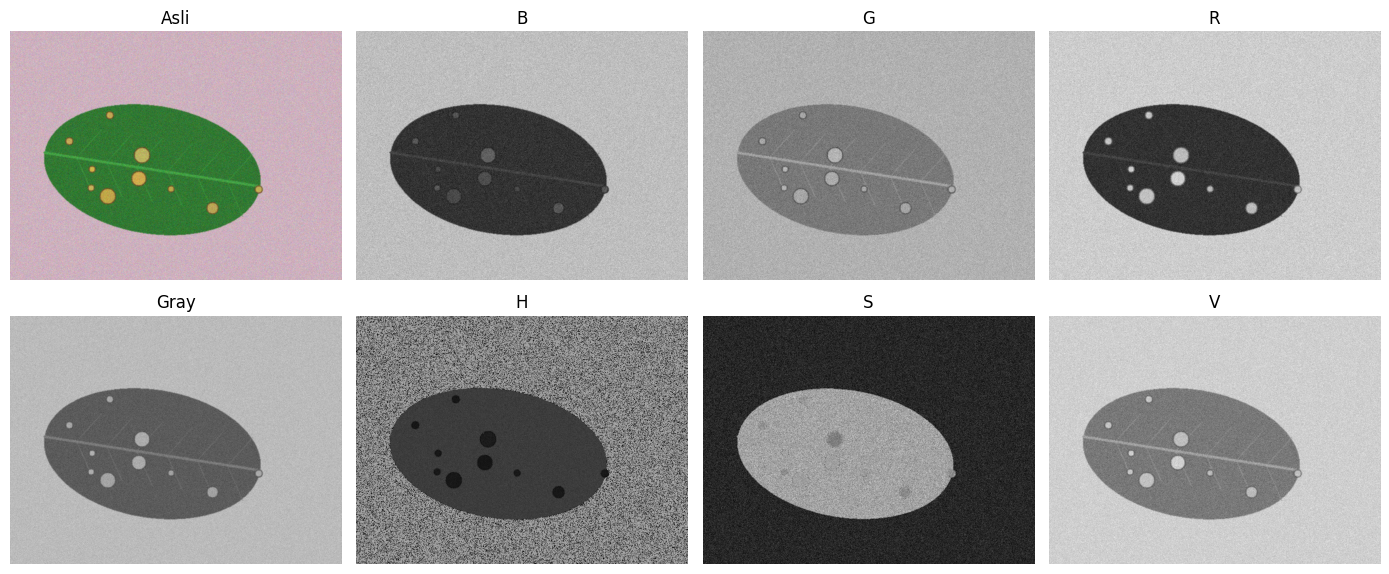

In [ ]:
import cv2
from utils_cv import baca, tampil, kontras_bercak

nama = "teh_041.png"                 # kelas berat, kondisi normal
img = baca(f"../data/sintetis/citra/{nama}")
md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
b, g, r = cv2.split(img)
h, s, v = cv2.split(hsv)
kanal = {"B": b, "G": g, "R": r, "Gray": gray, "H": h, "S": s, "V": v}

tampil([img] + list(kanal.values()), ["Asli"] + list(kanal.keys()),
       baris=2, ukuran=(14, 6))
for nm, c in kanal.items():
    print(f"KB kanal {nm:4s}: {kontras_bercak(c, md, mb):.2f}")

**2.2 Eksperimen sampling dan kuantisas**

In [ ]:
import numpy as np
# sampling: perkecil lalu perbesar kembali ke ukuran semula
for fx in [0.5, 0.2, 0.1, 0.05]:
    kecil = cv2.resize(gray, None, fx=fx, fy=fx, interpolation=cv2.INTER_AREA)
    besar = cv2.resize(kecil, gray.shape[::-1],
                       interpolation=cv2.INTER_NEAREST)
    print(f"fx={fx}: ukuran {kecil.shape}, KB={kontras_bercak(besar, md, mb):.2f}")


# kuantisasi: sisakan k bit
for k in [1, 2, 3, 4, 8]:
    langkah = 256 // (2 ** k)
    kuant = (gray // langkah) * langkah
    print(f"k={k}: {len(np.unique(kuant))} level, "
          f"KB={kontras_bercak(kuant, md, mb):.2f}")

fx=0.5: ukuran (240, 320), KB=6.89
fx=0.2: ukuran (96, 128), KB=5.88
fx=0.1: ukuran (48, 64), KB=3.76
fx=0.05: ukuran (24, 32), KB=1.71
k=1: 2 level, KB=8.54
k=2: 4 level, KB=8.43
k=3: 6 level, KB=3.45
k=4: 11 level, KB=4.80
k=8: 163 level, KB=5.32


**2.3 Rata-rata KB per kanal dan per kondisi**

In [ ]:
import pandas as pd

def semua_kanal(img):
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    b, g, r = cv2.split(img)
    h, s, v = cv2.split(hsv)

    return {"B": b,"G": g,"R": r,
            "Gray": cv2.cvtColor(img, cv2.COLOR_BGR2GRAY),
            "H": h,"S": s,"V": v}

label = pd.read_csv("../data/sintetis/label.csv")
baris = []
for _, d in label[label.kelas == "berat"].iterrows():
    im = baca(f"../data/sintetis/citra/{d.nama_file}")
    m_d = cv2.imread(f"../data/sintetis/mask_daun/{d.nama_file}", 0)
    m_b = cv2.imread(f"../data/sintetis/mask_bercak/{d.nama_file}", 0)
    kb = {k: kontras_bercak(c, m_d, m_b) for k, c in semua_kanal(im).items()}
    kb["kondisi"] = d.kondisi_cahaya
    baris.append(kb)
tabel_kb = (pd.DataFrame(baris).groupby("kondisi").mean().round(2))
print(tabel_kb)
tabel_kb.to_csv("../hasil/b2_kb_kanal.csv")

                   B     G      R  Gray     H     S     V
kondisi                                                  
bayangan        1.92  0.77   6.18  2.29  4.73  1.12  1.43
gelap           1.80  1.26  10.78  4.68  6.31  1.09  3.43
kontras_rendah  1.08  0.62   4.52  2.63  2.50  0.31  1.68
normal          1.77  1.06   9.86  4.74  7.49  0.97  2.72
terang          3.03  0.63   8.05  4.13  6.86  1.66  1.97
